# Laboratorio 9
**CC3092 – Deep Learning**

VAE y modelo de difusión (con guía sin clasificador) sobre Fashion-MNIST, más una verificación numérica de pass@k.

Se utilizó Claude Code (Anthropic) para construir un notebook para 'rellenar celdas' tal como laboratorios anteriores. Las instrucciones fueron específicas, dejar las partes "core" del laboratorioo que cubran los conceptos vistos en clase para implementar a mano mientras que cosas como obtener el dataset, batching, etc. ya entran llenas.

In [1]:
import math, os, random, time
from contextlib import contextmanager
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

os.makedirs("ckpt", exist_ok=True)
FORCE_RETRAIN = False   # True ignora los checkpoints guardados en ckpt/

CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# ---------- utilidades de visualización / batching (no son parte del contenido evaluado) ----------
def batches(*tensors, bs, shuffle=True):
    """Itera mini-batches de tensores que ya viven en `device`."""
    n = tensors[0].shape[0]
    idx = torch.randperm(n, device=tensors[0].device) if shuffle else torch.arange(n, device=tensors[0].device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        yield tuple(t[j] for t in tensors)

def tile(imgs, nrow, pad=1, pad_val=1.0):
    """(N,1,28,28) -> una sola imagen 2D con `nrow` filas (numpy)."""
    imgs = imgs.detach().cpu().squeeze(1).numpy()
    n, h, w = imgs.shape
    ncol = math.ceil(n / nrow)
    canvas = np.full((nrow * (h + pad) + pad, ncol * (w + pad) + pad), pad_val, dtype=np.float32)
    for k in range(n):
        r, c = divmod(k, ncol)
        canvas[pad + r * (h + pad): pad + r * (h + pad) + h, pad + c * (w + pad): pad + c * (w + pad) + w] = imgs[k]
    return canvas

def show(imgs, nrow, title=None, ax=None, vmin=0, vmax=1):
    ax = ax or plt.gca()
    ax.imshow(tile(imgs, nrow, pad_val=vmax), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.axis("off")

to01 = lambda x: ((x + 1) / 2).clamp(0, 1)      # [-1,1] -> [0,1]

device: cuda | torch 2.14.1+cu130


> **Semilla fija:** `SEED = 42` (Python, NumPy y PyTorch/CUDA). Se reutiliza en entrenamiento, muestreo y métricas.
>
> **Convención:** cada pregunta del PDF tiene un encabezado **Pregunta** y su respuesta escrita un encabezado **Respuesta**.

# Task 1 — Autoencoder variacional (Entrega parcial)

## Task 1.1 — Datos
Fashion-MNIST escalado a $[0,1]$, últimos 5 000 ejemplos de train como validación. Todo se guarda como tensores en GPU (el dataset es diminuto), así que no hace falta `DataLoader`.

train: (55000, 1, 28, 28) | val: (5000, 1, 28, 28) | rango: 0.0 1.0
clases en val: [521, 497, 490, 508, 527, 503, 467, 450, 515, 522]


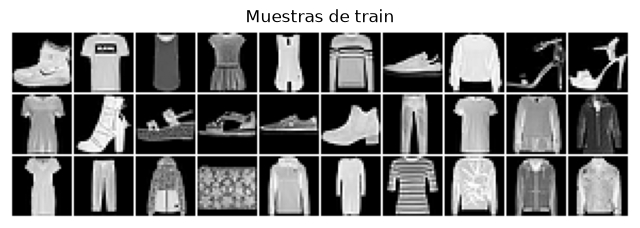

In [2]:
batch_size  = 128
latent_dim  = 2
epochs      = 20
lr          = 1e-3
beta_values = [0.1, 1.0, 10.0]

train_full = datasets.FashionMNIST("data", train=True,  download=True)
test_set   = datasets.FashionMNIST("data", train=False, download=True)

X_all = (train_full.data.float() / 255.0).unsqueeze(1)      # (60000,1,28,28) en [0,1]
y_all = train_full.targets.clone()

X_train, y_train = X_all[:-5000].to(device), y_all[:-5000].to(device)
X_val,   y_val   = X_all[-5000:].to(device), y_all[-5000:].to(device)
print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape), "| rango:", X_train.min().item(), X_train.max().item())
print("clases en val:", torch.bincount(y_val).tolist())

fig, ax = plt.subplots(figsize=(8, 3))
show(X_train[:30], nrow=3, title="Muestras de train", ax=ax); plt.show()

## Task 1.2 — Modelo y pérdida
Escribir:
- `reparameterize`: $z=\mu+\sigma\odot\epsilon$
- `kl_divergence`: KL cerrada entre $\mathcal N(\mu,\mathrm{diag}(\sigma^2))$ y $\mathcal N(0,I)$, sumada sobre dimensiones latentes → un valor **por imagen**
- `vae_loss`: $\|x-\hat x\|^2$ (suma sobre 784 píxeles) $+\ \beta D_{KL}$

**Arquitectura:** VAE completamente conectado, `latent_dim = 2`.
- **Encoder:** Flatten → 784→512 → ReLU → 512→256 → ReLU
- **Heads:** `fc_mu` y `fc_lv`, cada uno 256→2 (μ y log σ²)
- **Decoder:** 2→256 → ReLU → 256→512 → ReLU → 512→784 → Sigmoid → (1, 28, 28)

In [ ]:
# Reparametrización: z = mu + sigma * eps
def reparameterize(mu, logvar):
    return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

# KL cerrada entre N(mu, sigma^2) y N(0, I), sumada sobre dims latentes -> (B,)
def kl_divergence(mu, logvar):
    return -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp(), dim=1)

# Pérdida: error cuadrático (suma sobre pixeles) + beta * KL, promediado por batch
def vae_loss(x, x_hat, mu, logvar, beta):
    recon = ((x - x_hat) ** 2).flatten(1).sum(1)
    kl = kl_divergence(mu, logvar)
    return (recon + beta * kl).mean(), recon.mean(), kl.mean()

class VAE(nn.Module):
    def __init__(self, latent_dim=2, hidden=512):
        super().__init__()
        # Encoder: 784 -> 512 -> 256
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 256), nn.ReLU())
        # Heads: 256 -> latent_dim (media y log-varianza)
        self.fc_mu = nn.Linear(256, latent_dim); self.fc_lv = nn.Linear(256, latent_dim)
        # Decoder: latent_dim -> 256 -> 512 -> 784, Sigmoid -> [0,1]
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x); return self.fc_mu(h), self.fc_lv(h)

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(reparameterize(mu, logvar)), mu, logvar

In [4]:
@torch.no_grad()
def evaluate_vae(model, X, beta, bs=1000):
    """Reconstrucción y KL promedio por imagen (un z muestreado por imagen)."""
    model.eval()
    rec = kl = 0.0
    for (xb,) in batches(X, bs=bs, shuffle=False):
        x_hat, mu, logvar = model(xb)
        _, r, k = vae_loss(xb, x_hat, mu, logvar, beta)
        rec += r.item() * len(xb); kl += k.item() * len(xb)
    return rec / len(X), kl / len(X)


def train_vae(beta, epochs=epochs, seed=SEED):
    path = f"ckpt/vae_beta{beta}.pt"
    torch.manual_seed(seed)
    model = VAE(latent_dim).to(device)
    if os.path.exists(path) and not FORCE_RETRAIN:
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["state"]); print(f"[β={beta}] cargado de {path}")
        return model, ck["hist"]
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "train_recon", "train_kl", "val_recon", "val_kl"]}
    for ep in range(epochs):
        model.train(); tl = tr = tk = 0.0
        for (xb,) in batches(X_train, bs=batch_size):
            x_hat, mu, logvar = model(xb)
            loss, r, k = vae_loss(xb, x_hat, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(xb); tr += r.item() * len(xb); tk += k.item() * len(xb)
        n = len(X_train)
        vr, vk = evaluate_vae(model, X_val, beta)
        for key, v in zip(hist, [tl / n, tr / n, tk / n, vr, vk]): hist[key].append(v)
        print(f"[β={beta}] ep {ep+1:2d}/{epochs} | loss {tl/n:7.2f} | val recon {vr:7.2f} | val KL {vk:6.2f}")
    torch.save({"state": model.state_dict(), "hist": hist}, path)
    return model, hist

In [5]:
vaes, hists = {}, {}
for b in beta_values:
    vaes[b], hists[b] = train_vae(b)

[β=0.1] cargado de ckpt/vae_beta0.1.pt
[β=1.0] cargado de ckpt/vae_beta1.0.pt
[β=10.0] cargado de ckpt/vae_beta10.0.pt


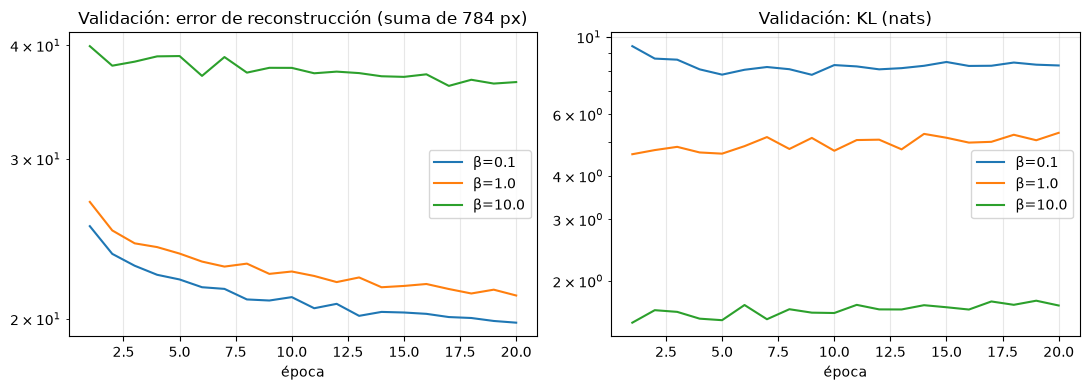

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for b in beta_values:
    axs[0].plot(range(1, epochs + 1), hists[b]["val_recon"], label=f"β={b}")
    axs[1].plot(range(1, epochs + 1), hists[b]["val_kl"], label=f"β={b}")
axs[0].set(title="Validación: error de reconstrucción (suma de 784 px)", xlabel="época", yscale="log")
axs[1].set(title="Validación: KL (nats)", xlabel="época", yscale="log")
for a in axs: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Task 1.3 — Figuras

**(a)** Dispersión de $\mu$ en validación, coloreada por clase.

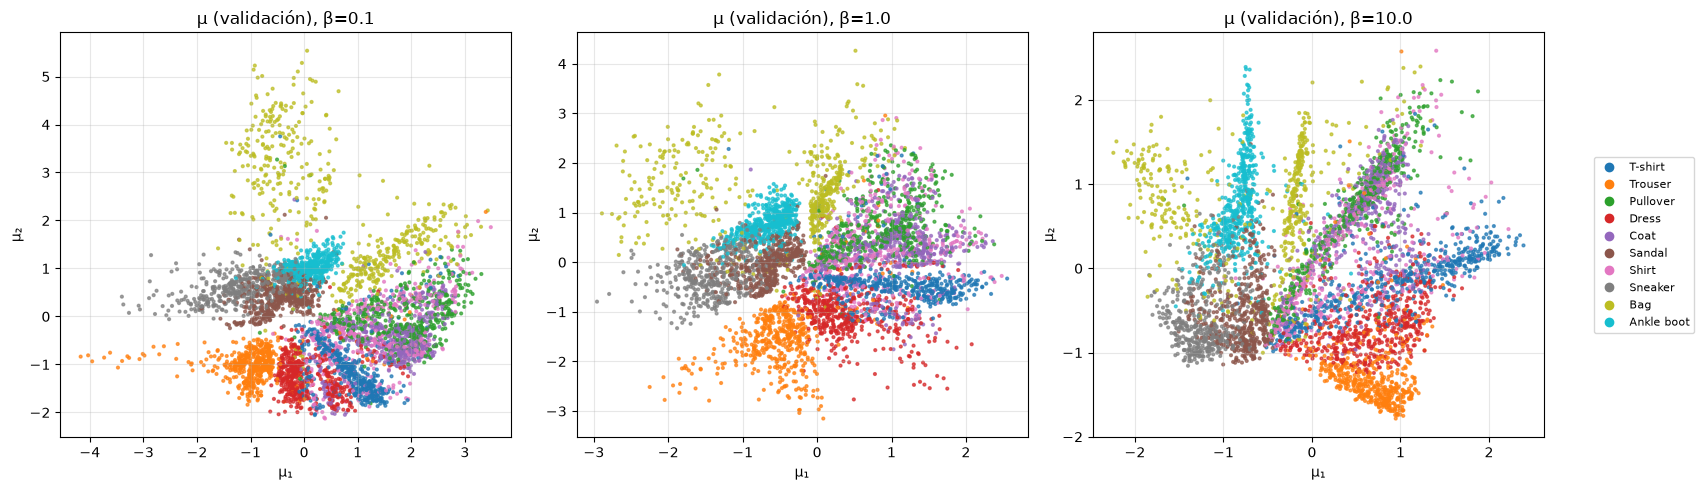

In [7]:
@torch.no_grad()
def encode_all(model, X, bs=1000):
    model.eval()
    mus, lvs = zip(*[model.encode(xb) for (xb,) in batches(X, bs=bs, shuffle=False)])
    return torch.cat(mus), torch.cat(lvs)

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
for ax, b in zip(axs, beta_values):
    mu, _ = encode_all(vaes[b], X_val)
    mu = mu.cpu().numpy()
    sc = ax.scatter(mu[:, 0], mu[:, 1], c=y_val.cpu().numpy(), cmap="tab10", s=4, alpha=.7)
    ax.set(title=f"μ (validación), β={b}", xlabel="μ₁", ylabel="μ₂"); ax.grid(alpha=.3)
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=n) for i, n in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, loc="center right", fontsize=8)
plt.tight_layout(rect=[0, 0, .92, 1]); plt.show()

**(b)** Cuadrícula $15\times15$ de $z\in[-3,3]^2$ decodificada, $\beta=1$ (la fila superior corresponde a $z_2=+3$).

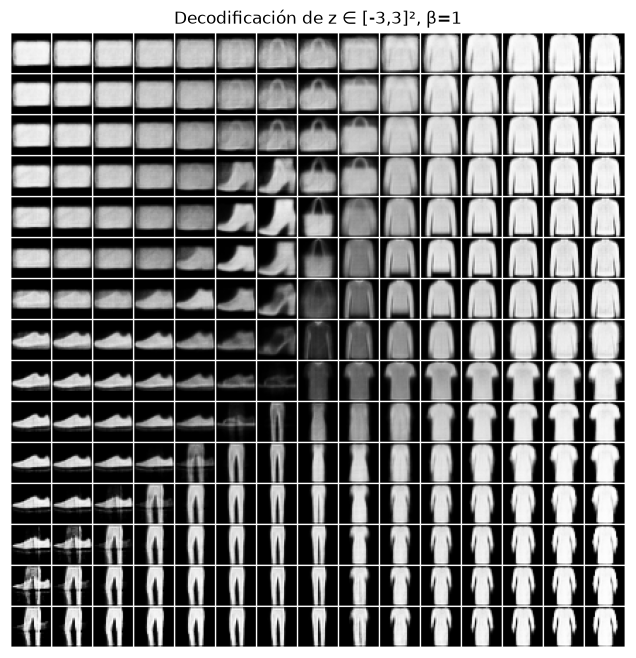

In [8]:
@torch.no_grad()
def latent_grid(model, n=15, lim=3.0):
    model.eval()
    zs = torch.linspace(-lim, lim, n, device=device)
    z2, z1 = torch.meshgrid(torch.flip(zs, [0]), zs, indexing="ij")     # filas: z2 de +lim a -lim
    z = torch.stack([z1.reshape(-1), z2.reshape(-1)], dim=1)
    return model.decode(z)

fig, ax = plt.subplots(figsize=(8, 8))
show(latent_grid(vaes[1.0]), nrow=15, title="Decodificación de z ∈ [-3,3]², β=1", ax=ax); plt.show()

**(c)** 64 imágenes generadas con $z\sim\mathcal N(0,I)$ por cada $\beta$.

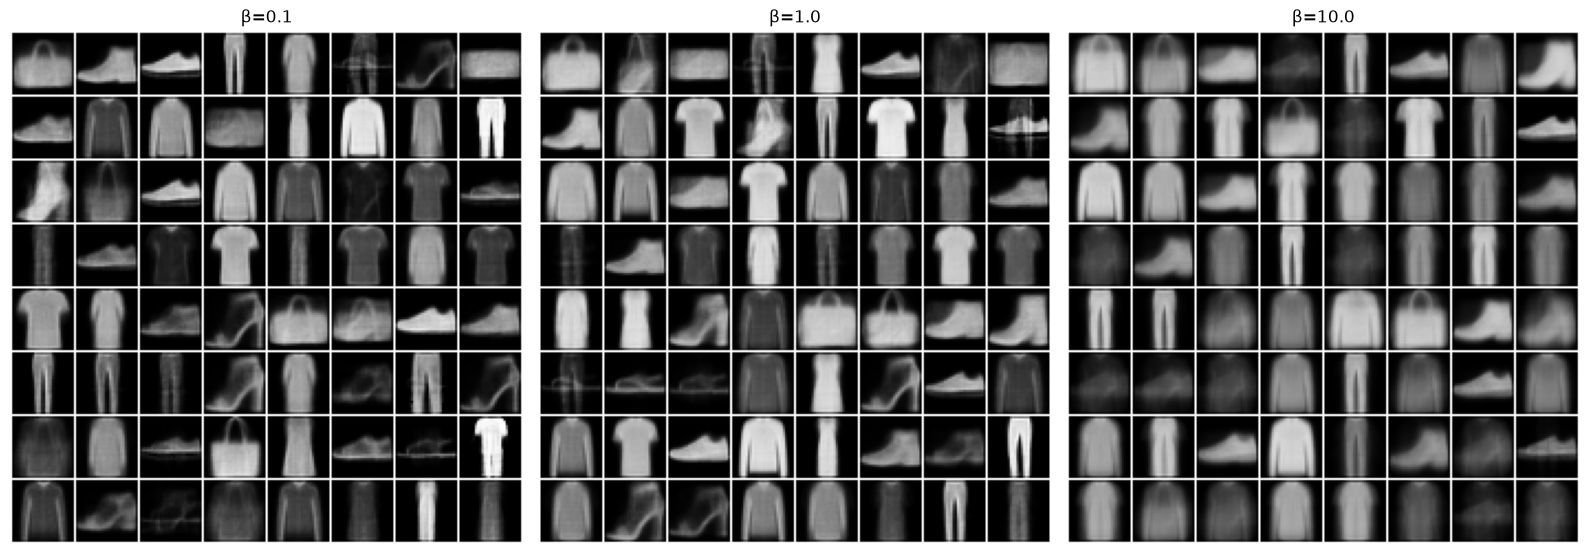

In [9]:
@torch.no_grad()
def vae_sample(model, n, seed=None):
    model.eval()
    g = torch.Generator(device=device)
    if seed is not None: g.manual_seed(seed)
    z = torch.randn(n, latent_dim, device=device, generator=g)
    return model.decode(z)

fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, b in zip(axs, beta_values):
    show(vae_sample(vaes[b], 64, seed=SEED), nrow=8, title=f"β={b}", ax=ax)
plt.tight_layout(); plt.show()

**(d)** Interpolación entre dos imágenes de validación de clases distintas (8 puntos intermedios), $\beta=1$: píxeles vs. espacio latente (sobre $\mu$).

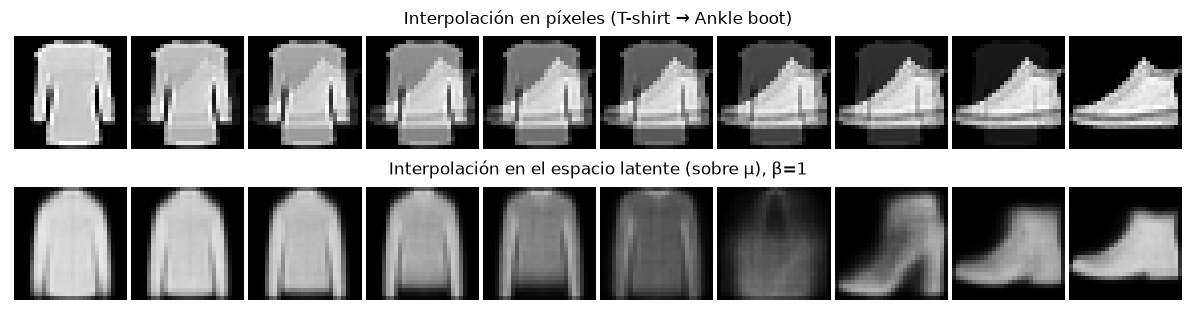

In [10]:
INTERP_CLASSES = (0, 9)      # T-shirt -> Ankle boot (cambie si desea otro par)
ia = int((y_val == INTERP_CLASSES[0]).nonzero()[0]); ib = int((y_val == INTERP_CLASSES[1]).nonzero()[0])
xa, xb_ = X_val[ia:ia + 1], X_val[ib:ib + 1]
alphas_i = torch.linspace(0, 1, 10, device=device)           # 2 extremos + 8 intermedios

@torch.no_grad()
def interpolations(model):
    model.eval()
    pix = torch.stack([(1 - a) * xa[0] + a * xb_[0] for a in alphas_i])
    mu_a, _ = model.encode(xa); mu_b, _ = model.encode(xb_)
    lat = model.decode(torch.stack([(1 - a) * mu_a[0] + a * mu_b[0] for a in alphas_i]))
    return pix, lat

pix_interp, lat_interp = interpolations(vaes[1.0])
fig, axs = plt.subplots(2, 1, figsize=(13, 3.2))
show(pix_interp, nrow=1, title=f"Interpolación en píxeles ({CLASS_NAMES[INTERP_CLASSES[0]]} → {CLASS_NAMES[INTERP_CLASSES[1]]})", ax=axs[0])
show(lat_interp, nrow=1, title="Interpolación en el espacio latente (sobre μ), β=1", ax=axs[1])
plt.tight_layout(); plt.show()

## Task 1.4 — Análisis

### Pregunta 1.4(a)

**(a)** Tabla de reconstrucción y KL finales de validación, KL en bits vs. $\log_2 10\approx3.32$ bits.

In [11]:
rows = []
for b in beta_values:
    r, k = evaluate_vae(vaes[b], X_val, b)
    rows.append({"β": b, "recon (val)": r, "KL nats (val)": k, "KL bits (val)": k / math.log(2)})
tab_vae = pd.DataFrame(rows).set_index("β")
print(f"log2(10) = {math.log2(10):.3f} bits")
tab_vae.round(3)

log2(10) = 3.322 bits


,recon (val),KL nats (val),KL bits (val)
β,,,
0.1,19.808,8.277,11.941
1.0,21.247,5.308,7.658
10.0,36.765,1.700,2.452


#### Respuesta 1.4(a)

Al subir $\beta$ la reconstrucción empeora y el KL baja: recon 19.8 $\rightarrow$ 21.2 $\rightarrow$ 36.8 y KL 8.28 $\rightarrow$ 5.31 $\rightarrow$ 1.70 nats (11.9 $\rightarrow$ 7.7 $\rightarrow$ 2.5 bits) para β = 0.1, 1, 10. Con β pequeño el modelo prioriza reconstruir y se aleja del prior; con β grande el término KL domina y el código latente transmite menos información.

Para β = 0.1 y β = 1 el KL (11.9 y 7.7 bits) supera $\text{log}_2 10 \approx 3.32$ bits, así que hay capacidad de sobra para codificar la clase. Para β = 10 el KL es 2.45 bits < 3.32, el código no alcanza para identificar la clase de una imagen de forma fiable y además esos bits deben describir también la forma y el estilo. Esto coincide con el diagrama de dispersión de β = 10: las clases de forma muy distinta (Trouser, Bag, Ankle boot, Sneaker/Sandal) ocupan regiones propias, pero T-shirt, Pullover, Coat, Shirt y Dress se superponen en una sola zona. Es decir, el código distingue solo ~5–6 grupos (2^2.45 ≈ 5.5) en lugar de 10 clases.

### Pregunta 1.4(b)

**(b)** KL por Monte Carlo ($10^5$ muestras de $q(z|x)$, promedio de $\log q(z)-\log p(z)$) vs. KL cerrada, $\beta=1$, una imagen de validación.

In [12]:
@torch.no_grad()
def kl_monte_carlo(mu, logvar, n=100_000, seed=SEED):
    """KL ≈ mean[ log q(z|x) - log p(z) ], z ~ q(z|x). Log-densidades gaussianas escritas a mano (float64)."""
    g = torch.Generator(device=device); g.manual_seed(seed)
    mu, logvar = mu.double(), logvar.double()
    eps = torch.randn(n, mu.shape[-1], device=device, dtype=torch.float64, generator=g)
    z = mu + torch.exp(0.5 * logvar) * eps
    log2pi = math.log(2 * math.pi)
    log_q = (-0.5 * (log2pi + logvar + (z - mu) ** 2 / logvar.exp())).sum(1)
    log_p = (-0.5 * (log2pi + z ** 2)).sum(1)
    diff = log_q - log_p
    return diff.mean().item(), (diff.std() / math.sqrt(n)).item()      # estimación y error estándar MC

IMG_IDX = 0
mu1, lv1 = vaes[1.0].eval().encode(X_val[IMG_IDX:IMG_IDX + 1])
kl_cf = kl_divergence(mu1, lv1).item()
kl_mc, kl_se = kl_monte_carlo(mu1[0], lv1[0])
print(f"μ={mu1.detach().cpu().numpy().round(3)}, σ={torch.exp(0.5*lv1).detach().cpu().numpy().round(3)}")
print(f"KL cerrada     = {kl_cf:.5f}")
print(f"KL Monte Carlo = {kl_mc:.5f}  (± {kl_se:.5f} error estándar)")
print(f"error relativo = {abs(kl_mc - kl_cf) / abs(kl_cf):.3e} | |diff| / SE = {abs(kl_mc - kl_cf) / kl_se:.2f}")

μ=[[1.761 0.214]], σ=[[0.164 0.079]]
KL cerrada     = 4.93679
KL Monte Carlo = 4.93691  (± 0.00324 error estándar)
error relativo = 2.412e-05 | |diff| / SE = 0.04


#### Respuesta 1.4(b)

Para una imagen de validación, con el modelo $\beta=1$ ($\mu=[1.761,\,0.214]$, $\sigma=[0.164,\,0.079]$):

| Método | KL (nats) |
|---|---|
| Forma cerrada | 4.93679 |
| Monte Carlo ($10^5$ muestras) | 4.93691 ± 0.00324 |

**Error relativo:** $2.4\times10^{-5}$ (diferencia absoluta $\approx 1.2\times10^{-4}$).

**¿Es compatible con la variabilidad Monte Carlo?** Sí. El error estándar del estimador es $\text{SE}=s/\sqrt{N}\approx0.0032$, y la diferencia observada es solo $0.04$ SE. Una fluctuación típica sería de alrededor de 1 SE, así que la diferencia está muy dentro de lo esperado.

Esto confirma que la fórmula cerrada
$$D_{KL}=\tfrac12\sum_j\left(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2\right)$$
está bien implementada.

### Pregunta 1.4(c)

**(c)** Región del espacio latente no reconocible; punto medio de las interpolaciones.

#### Respuesta 1.4(c)

Con $\beta=1$ las imágenes de las esquinas de la cuadrícula siguen siendo reconocibles. Bolsos arriba a la izquierda, zapatos en el centro-izquierda, pantalones abajo a la izquierda y prendas superiores a la derecha. La región no reconocible está cerca del origen, en la frontera entre las zonas de zapato (Sneaker/Ankle boot), pantalón y prendas superiores (aprox. $z_1\in[-1,0]$, $z_2\in[-1,0.5]$). Ahí el decoder produce imágenes oscuras y tenues, sin forma de ninguna clase.

El término KL empuja los posteriores $q(z|x)$ hacia $\mathcal N(0,I)$, de modo que las clases quedan juntas y solapadas alrededor del origen. En una frontera, el mismo $z$ puede venir de imágenes de clases distintas y como la pérdida es un error cuadrático, el decoder aprende a producir el promedio de ellas. Con $\beta$ más grande el overlap sería mayor y más zonas se verían así; con $\beta$ pequeño habría huecos con menos datos donde el decoder se entrena poco.

En píxeles, el punto medio es una superposición lineal de las dos imágenes, se ven a la vez las mangas de la camiseta y la silueta de la bota, cada una al 50 % de intensidad. Esto claramente no es una imagen plausible de ninguna clase. En el espacio latente, el punto medio $\mu=\tfrac12(\mu_a+\mu_b)$ se decodifica con una red no lineal, así que no hay superposición. La secuencia se mantiene como una prenda de manga larga que se va desvaneciendo, pasa por una mancha oscura y borrosa (el punto medio cae en la frontera entre clases, la región descrita arriba) y luego cambia de golpe a una bota. Difieren porque la interpolación en píxeles es lineal en el espacio de imagen, mientras que la latente es lineal en $z$ pero pasa por el decoder, que mapea la zona entre clases a su "imagen promedio" borrosa y no a una mezcla de ambas.

### Pregunta 1.4(d)

**(d)** Nitidez = magnitud media de la diferencia entre píxeles horizontalmente adyacentes, sobre 1 000 imágenes reales y 1 000 generadas por cada $\beta$.

In [13]:
def sharpness(x):
    """Media de |x[..., j+1] - x[..., j]|. x en [0,1], shape (N,1,28,28)."""
    return (x[..., 1:] - x[..., :-1]).abs().mean().item()

sharp_real = sharpness(X_val[:1000])
sharp_vae = {b: sharpness(vae_sample(vaes[b], 1000, seed=SEED)) for b in beta_values}
tab_sharp = pd.DataFrame({"nitidez": {"real": sharp_real, **{f"VAE β={b}": v for b, v in sharp_vae.items()}}})
tab_sharp.round(4)

,nitidez
real,0.0891
VAE β=0.1,0.0446
VAE β=1.0,0.0501
VAE β=10.0,0.0439


#### Respuesta 1.4(d)

**Nitidez** (media de $|x_{j+1}-x_j|$, 1 000 imágenes cada una):

| Real | VAE $\beta=0.1$ | VAE $\beta=1$ | VAE $\beta=10$ |
|---|---|---|---|
| 0.0891 | 0.0446 | 0.0501 | 0.0439 |

Las muestras del VAE tienen alrededor de la mitad de la nitidez de las imágenes reales.

**Relación con $\sigma_x^2$.** Con decoder gaussiano, el negativo del ELBO es proporcional a $\|x-\hat x\|^2 + 2\sigma_x^2 D_{KL}$. Mi pérdida es $\mathcal L_\beta=\|x-\hat x\|^2+\beta D_{KL}$, así que $2\sigma_x^2=\beta$, es decir, $\sigma_x^2=\beta/2$.

**Por qué salen borrosas.** Con $\beta=1$, el modelo supone un ruido por píxel de $\sigma_x\approx0.7$, enorme para imágenes en $[0,1]$. Por eso casi no se penaliza producir imágenes suavizadas. Además, al entrenar con error cuadrático, el decoder aprende la media $\mathbb E[x\mid z]$. Esa media promedia los bordes y texturas posibles, y el resultado es borroso. Esto explica que todas las muestras pierdan cerca de la mitad de la nitidez.

La diferencia entre valores de $\beta$ es pequeña y no monótona (0.044–0.050, una sola semilla), así que no permite sacar conclusiones sobre el efecto de $\beta$.

# Task 2 — Proceso forward de difusión (Entrega parcial)

## Task 2.1 — Calendario y fórmula cerrada
Datos escalados a $[-1,1]$. Convención de índices: los tensores del calendario tienen longitud $T+1$ y se indexan **directamente por $t\in\{1,\dots,T\}$**; la posición 0 es un relleno ($\beta_0=0,\ \alpha_0=\bar\alpha_0=1$, es decir $x_0$).

In [ ]:
T          = 1000
beta_start = 1e-4
beta_end   = 0.02

# Datos a [-1,1]
X_train_pm = X_train * 2 - 1
X_val_pm   = X_val * 2 - 1

def schedule_from_betas(betas_1T):
    """betas (T,) -> dict con tensores de longitud T+1 indexados por t=1..T (índice 0 = x0)."""
    # double para precisión
    betas_1T = betas_1T.double()

    # β_0 = 0, así abar[t] = ᾱ_t
    betas = torch.cat([torch.zeros(1, dtype=torch.double), betas_1T])

    # α_t = 1 - β_t
    alphas = 1.0 - betas

    # ᾱ_t = ∏_{s=1}^t α_s
    abar = torch.cumprod(alphas, 0)

    # SNR_t = ᾱ_t / (1 - ᾱ_t)
    snr = abar / (1.0 - abar)

    # float32 en GPU, más copia double en CPU para sumas precisas
    d = {"betas": betas, "alphas": alphas, "abar": abar, "snr": snr}
    out = {k: v.float().to(device) for k, v in d.items()}
    out["betas_d"] = betas
    return out

# Calendario lineal
sched_lin = schedule_from_betas(torch.linspace(beta_start, beta_end, T))
abar_lin = sched_lin["abar"]
print("ᾱ_T (lineal) =", abar_lin[T].item())

ᾱ_T (lineal) = 4.0358307160204276e-05


In [ ]:
def q_sample(x0, t, eps, abar):
    # Forma cerrada del forward
    a = abar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * eps

## Task 2.2 — Verificación empírica de la fórmula cerrada
5 000 copias de una imagen $x_0$, 300 pasos $x_s=\sqrt{\alpha_s}x_{s-1}+\sqrt{\beta_s}\epsilon_s$ con ruido independiente, y comparación contra $\sqrt{\bar\alpha_{300}}x_0$ y $1-\bar\alpha_{300}$.

In [16]:
T_CHECK, N_COPIES, X0_IDX = 300, 5000, 0
g = torch.Generator(device=device); g.manual_seed(SEED)
x0 = X_train_pm[X0_IDX:X0_IDX + 1]                          # (1,1,28,28)
x = x0.expand(N_COPIES, -1, -1, -1).clone()
for s in range(1, T_CHECK + 1):
    eps = torch.randn(x.shape, device=device, generator=g)  # ruido independiente por paso y por copia
    x = sched_lin["alphas"][s].sqrt() * x + sched_lin["betas"][s].sqrt() * eps

mean_emp, var_emp = x.mean(0), x.var(0, unbiased=True)
mean_th = abar_lin[T_CHECK].sqrt() * x0[0]
var_th  = (1 - abar_lin[T_CHECK]) * torch.ones_like(var_emp)

err_mean_max = (mean_emp - mean_th).abs().max().item()
se_mean = (var_th / N_COPIES).sqrt().mean().item()          # error estándar del promedio de 5000 muestras
print(f"ᾱ_300 = {abar_lin[T_CHECK].item():.5f}  |  var teórica = {var_th.mean().item():.5f}")
print(f"error máximo |media_emp - media_teo| = {err_mean_max:.5f}")
print(f"error estándar esperado  σ/√N        = {se_mean:.5f}  -> máx/SE = {err_mean_max / se_mean:.2f}  (784 píxeles; ~3.2σ es lo esperado para el máximo)")
print(f"varianza empírica media = {var_emp.mean().item():.5f}  | |var_emp - var_teo| medio = {(var_emp - var_th).abs().mean().item():.5f}")

ᾱ_300 = 0.39642  |  var teórica = 0.60358
error máximo |media_emp - media_teo| = 0.03352
error estándar esperado  σ/√N        = 0.01099  -> máx/SE = 3.05  (784 píxeles; ~3.2σ es lo esperado para el máximo)
varianza empírica media = 0.60376  | |var_emp - var_teo| medio = 0.00936


#### Respuesta 2.2(b–c)

**Sí, es compatible.** Cada píxel de la media empírica promedia $N=5000$ muestras con varianza $1-\bar\alpha_{300}=0.60358$, así que

$$\text{SE}=\sqrt{0.60358/5000}=0.011.$$

El error máximo observado es $0.0335\approx3\,\text{SE}$. Como es el máximo sobre 784 píxeles, eso es lo esperado: el máximo de 784 normales suele estar cerca de $3.2\,\text{SE}$.

La varianza también coincide: $0.60376$ empírica frente a $0.60358$ teórica, con un error medio por píxel de $0.0094$. El error estándar de una varianza muestral es $(1-\bar\alpha_{300})\sqrt{2/(N-1)}\approx0.012$, así que el error medio es $\approx0.8$ veces ese SE, justo lo esperado ($\mathbb E|Z|\approx0.8$ para $Z\sim\mathcal N(0,1)$).

## Task 2.3 — Visualización y SNR

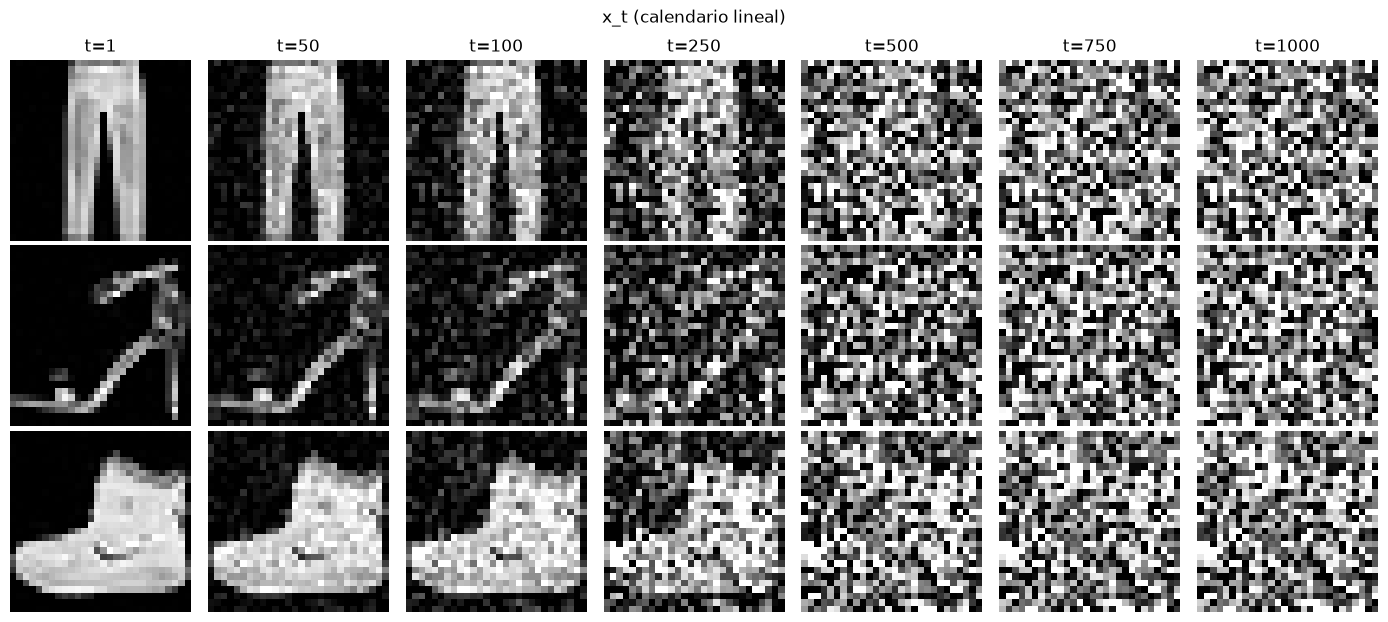

In [ ]:
T_VIS = [1, 50, 100, 250, 500, 750, 1000]
VIS_CLASSES = [1, 5, 9] # Trouser, Sandal, Ankle Boot
g = torch.Generator(device=device); g.manual_seed(SEED)

fig, axs = plt.subplots(len(VIS_CLASSES), len(T_VIS), figsize=(2 * len(T_VIS), 2.1 * len(VIS_CLASSES)))
for r, c in enumerate(VIS_CLASSES):
    x0c = X_train_pm[(y_train == c).nonzero()[0].item()][None]
    eps = torch.randn(x0c.shape, device=device, generator=g)
    for j, t in enumerate(T_VIS):
        xt = q_sample(x0c, torch.tensor([t], device=device), eps, abar_lin)
        axs[r, j].imshow(xt[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1); axs[r, j].axis("off")
        if r == 0: axs[r, j].set_title(f"t={t}")
    axs[r, 0].set_ylabel(CLASS_NAMES[c])
plt.suptitle("x_t (calendario lineal)"); plt.tight_layout(); plt.show()

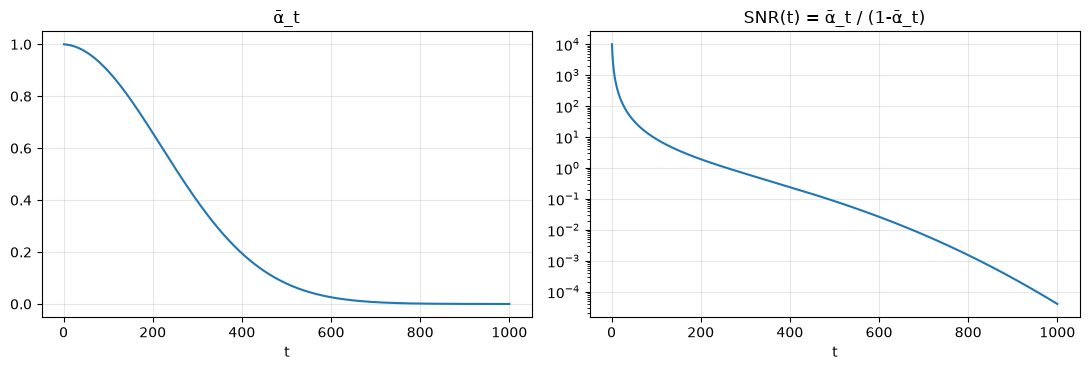

primer t con SNR(t) < 1    : 260
primer t con ᾱ_t < 0.01    : 674


In [18]:
def first_t(mask_1T):
    """Primer t (1..T) donde se cumple la condición; None si nunca."""
    idx = mask_1T.nonzero()
    return int(idx[0]) + 1 if len(idx) else None

ts = np.arange(1, T + 1)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(ts, abar_lin[1:].cpu()); axs[0].set(title="ᾱ_t", xlabel="t")
axs[1].semilogy(ts, sched_lin["snr"][1:].cpu()); axs[1].set(title="SNR(t) = ᾱ_t / (1-ᾱ_t)", xlabel="t")
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("primer t con SNR(t) < 1    :", first_t(sched_lin["snr"][1:] < 1))
print("primer t con ᾱ_t < 0.01    :", first_t(abar_lin[1:] < 0.01))

#### Respuesta 2.3(c)

- Primer $t$ con $\mathrm{SNR}(t)<1$: **$t=260$**
- Primer $t$ con $\bar\alpha_t<0.01$: **$t=674$**

## Task 2.4 — Segundo calendario
Claude fue el encargado de implementar el segundo calendario, se le indicó que tomara alguno popular, lo citara e implementara con alguna modificación.

In [19]:
def custom_betas(T, s=0.008):
    # Calendario coseno (Nichol & Dhariwal, 2021, 'Improved DDPM'): abar_t = f(t)/f(0), f(t) = cos^2(((t/T+s)/(1+s)) π/2),
    # y beta_t = 1 - abar_t/abar_{t-1}. Modificación: recorte de beta_t a [1e-5, 0.999] para que beta_t esté en (0,1).
    tt = torch.arange(T + 1, dtype=torch.double) / T
    f = torch.cos((tt + s) / (1 + s) * math.pi / 2) ** 2
    return (1 - f[1:] / f[:-1]).clamp(1e-5, 0.999)

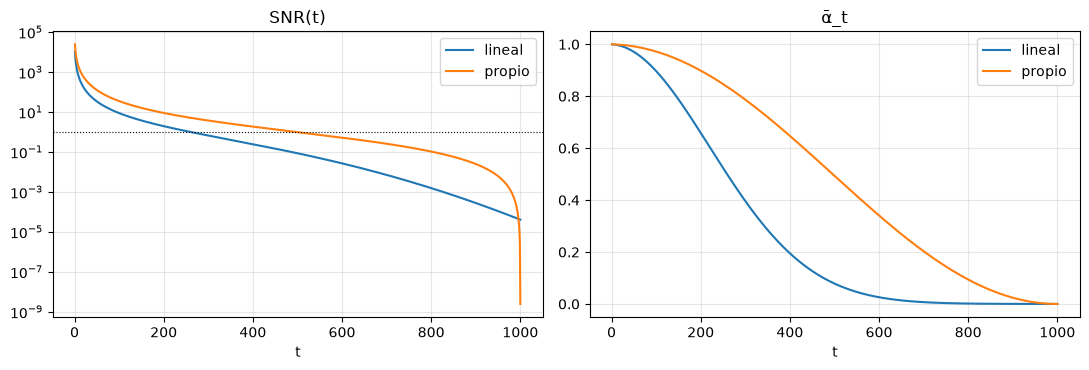

,ᾱ_T,primer t con SNR<1
lineal,4.035831e-05,260.0
propio,2.428767e-09,497.0


In [20]:
betas_c = custom_betas(T)
assert betas_c.shape == (T,) and ((betas_c > 0) & (betas_c < 1)).all(), "β_t debe estar en (0,1)"
sched_cus = schedule_from_betas(betas_c)
assert sched_cus["abar"][T] < 1e-3, "se requiere ᾱ_T < 1e-3"

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for name, sc in [("lineal", sched_lin), ("propio", sched_cus)]:
    axs[0].semilogy(ts, sc["snr"][1:].cpu(), label=name)
    axs[1].plot(ts, sc["abar"][1:].cpu(), label=name)
axs[0].axhline(1, color="k", ls=":", lw=.8)
axs[0].set(title="SNR(t)", xlabel="t"); axs[1].set(title="ᾱ_t", xlabel="t")
for a in axs: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

tab_sched = pd.DataFrame({name: {"ᾱ_T": sc["abar"][T].item(), "primer t con SNR<1": first_t(sc["snr"][1:] < 1)}
                          for name, sc in [("lineal", sched_lin), ("propio", sched_cus)]}).T
tab_sched

## Task 2.5 — Análisis

### Pregunta 2.5(a)

**(a)** Aproximación $\log\bar\alpha_T\approx-\sum_t\beta_t-\tfrac12\sum_t\beta_t^2$. Desarrolle a mano la suma aritmética y la integral de la progresión lineal (muestre los pasos en su informe); la celda siguiente solo da los valores numéricos **para contrastar**.

In [21]:
b = sched_lin["betas_d"][1:]
sum_b, sum_b2 = b.sum().item(), (b ** 2).sum().item()
log_abar_approx = -sum_b - 0.5 * sum_b2
print(f"Σβ_t (numérico)   = {sum_b:.5f}   | T(β0+β1)/2 = {T * (beta_start + beta_end) / 2:.5f}")
print(f"Σβ_t² (numérico)  = {sum_b2:.5f}  | T(β0²+β0β1+β1²)/3 (integral) = {T * (beta_start**2 + beta_start*beta_end + beta_end**2) / 3:.5f}")
print(f"ᾱ_T aprox = {math.exp(log_abar_approx):.4e} | ᾱ_T exacto (código) = {abar_lin[T].item():.4e}")

Σβ_t (numérico)   = 10.05000   | T(β0+β1)/2 = 10.05000
Σβ_t² (numérico)  = 0.13407  | T(β0²+β0β1+β1²)/3 (integral) = 0.13400
ᾱ_T aprox = 4.0386e-05 | ᾱ_T exacto (código) = 4.0358e-05


#### Respuesta 2.5(a)

Con $\beta_t$ lineal de $10^{-4}$ a $0.02$ y $T=1000$:

$$\sum_t\beta_t=\frac{T(\beta_1+\beta_T)}{2}=10.05,\qquad \sum_t\beta_t^2\approx\frac{T}{3}\left(\beta_1^2+\beta_1\beta_T+\beta_T^2\right)=0.1340.$$

$$\log\bar\alpha_T\approx-10.05-\tfrac12(0.1340)=-10.117\ \Rightarrow\ \bar\alpha_T\approx4.04\times10^{-5}.$$

El valor exacto del código es $4.0358\times10^{-5}$ (diferencia de $\approx0.07\%$, debida al término de tercer orden omitido). Las sumas calculadas en la celda coinciden con las hechas a mano.

### Pregunta 2.5(b)

**(b)** Pasos con $\mathrm{SNR}\in[0.01,100]$ por calendario.

In [22]:
def count_snr_range(sc, lo=0.01, hi=100.0):
    s = sc["snr"][1:]
    return int(((s >= lo) & (s <= hi)).sum()), int((s < lo).sum()), int((s > hi).sum())

tab_cnt = pd.DataFrame({name: dict(zip(["SNR∈[0.01,100]", "SNR<0.01 (≈ruido)", "SNR>100 (≈x0)"], count_snr_range(sc)))
                        for name, sc in [("lineal", sched_lin), ("propio", sched_cus)]}).T
tab_cnt

,"SNR∈[0.01,100]",SNR<0.01 (≈ruido),SNR>100 (≈x0)
lineal,647,326,27
propio,880,64,56


#### Respuesta 2.5(b)

| Calendario | SNR $\in[0.01,100]$ | SNR $<0.01$ | SNR $>100$ |
|---|---|---|---|
| Lineal | 647 | 326 | 27 |
| Coseno | 880 | 64 | 56 |

- **SNR $<0.01$:** $x_t\approx\epsilon$, así que predecir $\epsilon$ es trivial y aporta poco gradiente. Con $t$ uniforme, en el lineal son el 33 % de los sorteos, casi desperdiciados.
- **SNR $>100$:** $x_t\approx x_0$, así que aislar el ruido es muy difícil (es el intervalo con mayor MSE en la Task 3.2). Son pocos pasos (27 en el lineal, 2.7 % de los sorteos), así que su aporte total al entrenamiento es pequeño.
- **SNR $\in[0.01,100]$:** señal y ruido son comparables, y la tarea es informativa.

El coseno es más eficiente: el 88 % de sus pasos están en el rango útil, frente al 65 % del lineal, y desperdicia muchos menos en ruido puro (64 frente a 326).



### Pregunta 2.5(c)

**(c)** $\mathrm{Var}(x_t)=\bar\alpha_t\mathrm{Var}(x_0)+(1-\bar\alpha_t)$: demostración en su informe y verificación numérica sobre el train escalado a $[-1,1]$.

In [23]:
var_x0 = X_train_pm.var().item()
g = torch.Generator(device=device); g.manual_seed(SEED)
rows = []
for t in [1, 250, 500, 1000]:
    eps = torch.randn(X_train_pm.shape, device=device, generator=g)
    xt = q_sample(X_train_pm, torch.full((len(X_train_pm),), t, device=device, dtype=torch.long), eps, abar_lin)
    pred = abar_lin[t].item() * var_x0 + (1 - abar_lin[t].item())
    rows.append({"t": t, "Var empírica(x_t)": xt.var().item(), "predicción": pred,
                 "error relativo": abs(xt.var().item() - pred) / pred})
print(f"Var(x0) = {var_x0:.5f}")
pd.DataFrame(rows).set_index("t")

Var(x0) = 0.49826


,Var empírica(x_t),predicción,error relativo
t,,,
1,0.498311,0.498309,0.000004
250,0.736901,0.737045,0.000194
500,0.960402,0.960570,0.000175
1000,1.000266,0.999980,0.000286


#### Respuesta 2.5(c)

Como $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$, con $\epsilon$ independiente de $x_0$ (covarianza nula) y $\mathrm{Var}(\epsilon)=1$:

$$\mathrm{Var}(x_t)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t)\,\mathrm{Var}(\epsilon)+2\sqrt{\bar\alpha_t(1-\bar\alpha_t)}\,\mathrm{Cov}(x_0,\epsilon)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t).$$

Verificación con $\mathrm{Var}(x_0)=0.49826$:

| $t$ | Empírica | Predicción |
|---|---|---|
| 1 | 0.4983 | 0.4983 |
| 250 | 0.7369 | 0.7370 |
| 500 | 0.9604 | 0.9606 |
| 1000 | 1.0003 | 1.0000 |

Como $\bar\alpha_T\approx0$, se tiene $\mathrm{Var}(x_T)\approx1$ sin importar los datos. Esto es necesario porque el muestreo empieza en $x_T\sim\mathcal N(0,I)$. Si el proceso forward terminara en otra distribución, habría un desajuste entre entrenamiento y generación.

# Task 3 — Difusión condicional + guía sin clasificador (Entrega final)

## Task 3.1 — U-Net condicional
Entrada $x_t$ `(B,1,28,28)`, instante `t` `(B,)` (valores 1..T) y clase `c` `(B,)` en $\{0,\dots,10\}$ (10 = condición nula). Dos niveles (28×28 con 32 canales; 14×14 con 64), cuello de botella 14×14, subida con *skip connections* concatenadas, convolución final a 1 canal. Embedding sinusoidal de $t$ (misma fórmula de la Semana 6) + MLP, `nn.Embedding(11, d)` para la clase; la suma se inyecta con *broadcasting* en cada bloque.

Esta sección fue implementada utilizando IA, detallado en `AI.md`

In [ ]:
def sinusoidal_embedding(t, d):
    # Positional encoding (Semana 6) evaluado en t -> (B, d)
    half = d // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


class Block(nn.Module):
    """Dos convs 3x3 con GroupNorm+SiLU; el embedding (t + clase) se suma entre ambas."""
    def __init__(self, cin, cout, emb_dim):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1); self.n1 = nn.GroupNorm(8, cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1); self.n2 = nn.GroupNorm(8, cout)
        self.emb = nn.Linear(emb_dim, cout)
    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x)))
        h = h + self.emb(e)[:, :, None, None]
        return F.silu(self.n2(self.c2(h)))


class UNet(nn.Module):
    def __init__(self, emb_dim=128):
        super().__init__()
        self.emb_dim = emb_dim
        self.t_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.c_emb = nn.Embedding(11, emb_dim)               # 0..9 clases, 10 = clase nula
        self.enc1 = Block(1, 32, emb_dim)                    # 28x28, 32 ch
        self.enc2 = Block(32, 64, emb_dim)                   # 14x14, 64 ch
        self.mid  = Block(64, 64, emb_dim)                   # bottleneck 14x14
        self.dec2 = Block(64 + 64, 64, emb_dim)              # skip de enc2
        self.dec1 = Block(32 + 32, 32, emb_dim)              # skip de enc1
        self.out  = nn.Conv2d(32, 1, 1)
        self.down = nn.AvgPool2d(2)
        self.up   = nn.Upsample(scale_factor=2, mode="nearest")
        self.up_conv = nn.Conv2d(64, 32, 3, padding=1)

    def forward(self, x_t, t, c):
        e = self.t_mlp(sinusoidal_embedding(t, self.emb_dim)) + self.c_emb(c)
        s1 = self.enc1(x_t, e)                               # (B,32,28,28)
        s2 = self.enc2(self.down(s1), e)                     # (B,64,14,14)
        m  = self.mid(s2, e)
        d2 = self.dec2(torch.cat([m, s2], 1), e)             # (B,64,14,14)
        u  = self.up_conv(self.up(d2))                       # (B,32,28,28)
        d1 = self.dec1(torch.cat([u, s1], 1), e)
        return self.out(d1)

In [25]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model_diff = UNet().to(device)
_x = torch.randn(4, 1, 28, 28, device=device)
assert model_diff(_x, torch.randint(1, T + 1, (4,), device=device), torch.randint(0, 11, (4,), device=device)).shape == _x.shape
print("parámetros totales de la U-Net:", f"{count_params(model_diff):,}")

parámetros totales de la U-Net: 364,257


#### Respuesta 3.1

La U-Net condicional tiene **364,257 parámetros** entrenables.

## Task 3.2 — Entrenamiento
Por iteración: $t\sim U\{1,\dots,T\}$, $\epsilon\sim\mathcal N(0,I)$, $x_t$ con `q_sample`, clase → 10 con probabilidad `p_uncond`, MSE entre $\epsilon$ y la predicción.

In [ ]:
def diffusion_loss(model, x0, c, abar, T, p_uncond):
    # t ~ U{1..T} por imagen
    t = torch.randint(1, T + 1, (len(x0),), device=x0.device)

    # Ruido objetivo
    eps = torch.randn_like(x0)

    # x_t con la fórmula cerrada
    x_t = q_sample(x0, t, eps, abar)

    # Con prob. p_uncond reemplaza la clase por la nula (10)
    drop = torch.rand(len(x0), device=x0.device) < p_uncond
    c = torch.where(drop, torch.full_like(c, 10), c)

    # MSE entre el ruido real y el predicho
    return F.mse_loss(model(x_t, t, c), eps)

cargado de ckpt/unet.pt


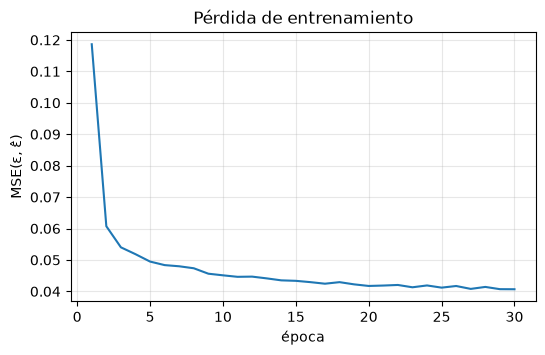

In [27]:
diff_epochs, diff_bs, diff_lr, p_uncond = 30, 128, 2e-4, 0.1

def train_diffusion(path="ckpt/unet.pt"):
    torch.manual_seed(SEED)
    model = UNet().to(device)
    if os.path.exists(path) and not FORCE_RETRAIN:
        ck = torch.load(path, map_location=device); model.load_state_dict(ck["state"])
        print("cargado de", path); return model, ck["losses"]
    opt = torch.optim.Adam(model.parameters(), lr=diff_lr)
    losses = []
    for ep in range(diff_epochs):
        model.train(); tot = 0.0
        for xb, yb in batches(X_train_pm, y_train, bs=diff_bs):
            loss = diffusion_loss(model, xb, yb, abar_lin, T, p_uncond)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        losses.append(tot / len(X_train_pm))
        print(f"ep {ep+1:2d}/{diff_epochs} | loss {losses[-1]:.4f}")
    torch.save({"state": model.state_dict(), "losses": losses}, path)
    return model, losses

model_diff, diff_losses = train_diffusion()
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(diff_losses) + 1), diff_losses)
plt.xlabel("época"); plt.ylabel("MSE(ε, ε̂)"); plt.title("Pérdida de entrenamiento"); plt.grid(alpha=.3); plt.show()

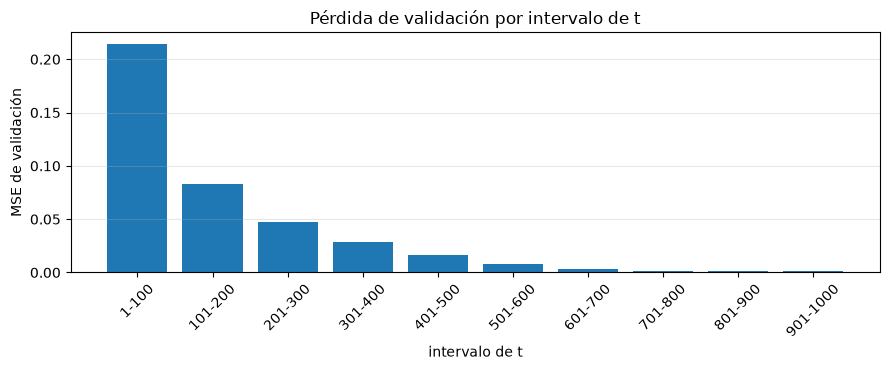

intervalo,1-100,101-200,201-300,301-400,401-500,501-600,601-700,701-800,801-900,901-1000
MSE val,0.2145,0.0826,0.0478,0.0287,0.0162,0.008,0.0036,0.0017,0.0011,0.001


In [28]:
@torch.no_grad()
def eval_loss_by_interval(model, X, y, n_int=10, width=100, repeats=2, seed=SEED):
    """MSE de validación (condicional con la clase verdadera) con t ~ U en cada intervalo de 100 pasos."""
    model.eval()
    g = torch.Generator(device=device); g.manual_seed(seed)
    out = []
    for k in range(n_int):
        lo, hi = k * width + 1, (k + 1) * width
        tot = 0.0
        for _ in range(repeats):
            for xb, yb in batches(X, y, bs=1000, shuffle=False):
                t = torch.randint(lo, hi + 1, (len(xb),), device=device, generator=g)
                eps = torch.randn(xb.shape, device=device, generator=g)
                tot += F.mse_loss(model(q_sample(xb, t, eps, abar_lin), t, yb), eps, reduction="sum").item()
        out.append(tot / (repeats * X.numel()))
    return out

val_loss_int = eval_loss_by_interval(model_diff, X_val_pm, y_val)
labels_int = [f"{100*k+1}-{100*(k+1)}" for k in range(10)]
plt.figure(figsize=(9, 3.8)); plt.bar(labels_int, val_loss_int)
plt.xticks(rotation=45); plt.ylabel("MSE de validación"); plt.xlabel("intervalo de t"); plt.title("Pérdida de validación por intervalo de t")
plt.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()
pd.DataFrame({"intervalo": labels_int, "MSE val": val_loss_int}).set_index("intervalo").round(4).T

## Task 3.3 / 3.4(a) — Muestreo ancestral y guía sin clasificador
$$x_{t-1}=\frac1{\sqrt{\alpha_t}}\Big(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\hat\epsilon\Big)+\sigma_t z,\quad \sigma_t^2=\beta_t,\ z=0\text{ en el último paso}$$
$$\tilde\epsilon=\epsilon_\theta(x_t,t,\varnothing)+w\,(\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing))$$

In [ ]:
def guided_eps(model, x, t, c, w):
    # w = 1: guía = modelo condicional puro, una sola evaluación
    if w == 1:
        return model(x, t, c)

    # Clase nula (10) para la rama incondicional
    null = torch.full_like(c, 10)

    # Ambas ramas en un solo forward: batch duplicado [incondicional ; condicional]
    eps_u, eps_c = model(torch.cat([x, x]), torch.cat([t, t]), torch.cat([null, c])).chunk(2)

    # eps_tilde = eps_u + w * (eps_c - eps_u)
    return eps_u + w * (eps_c - eps_u)


@torch.no_grad()
def ancestral_sample(model, labels, sched, w=1.0):
    betas, alphas, abar = sched["betas"], sched["alphas"], sched["abar"]

    # x_T ~ N(0, I)
    x = torch.randn(len(labels), 1, 28, 28, device=labels.device)

    for t in range(T, 0, -1):
        # Mismo t para todo el batch
        tt = torch.full((len(labels),), t, device=labels.device, dtype=torch.long)

        # Ruido predicho (con guía)
        eps = guided_eps(model, x, tt, labels, w)

        # Media del paso: (x_t - (1-α_t)/√(1-ᾱ_t) · eps) / √α_t
        x = (x - (1 - alphas[t]) / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()

        # Ruido σ_t z con σ_t² = β_t; z = 0 en el último paso (t = 1)
        if t > 1: x = x + betas[t].sqrt() * torch.randn_like(x)

    # Recorta a [-1,1]
    return x.clamp(-1, 1)

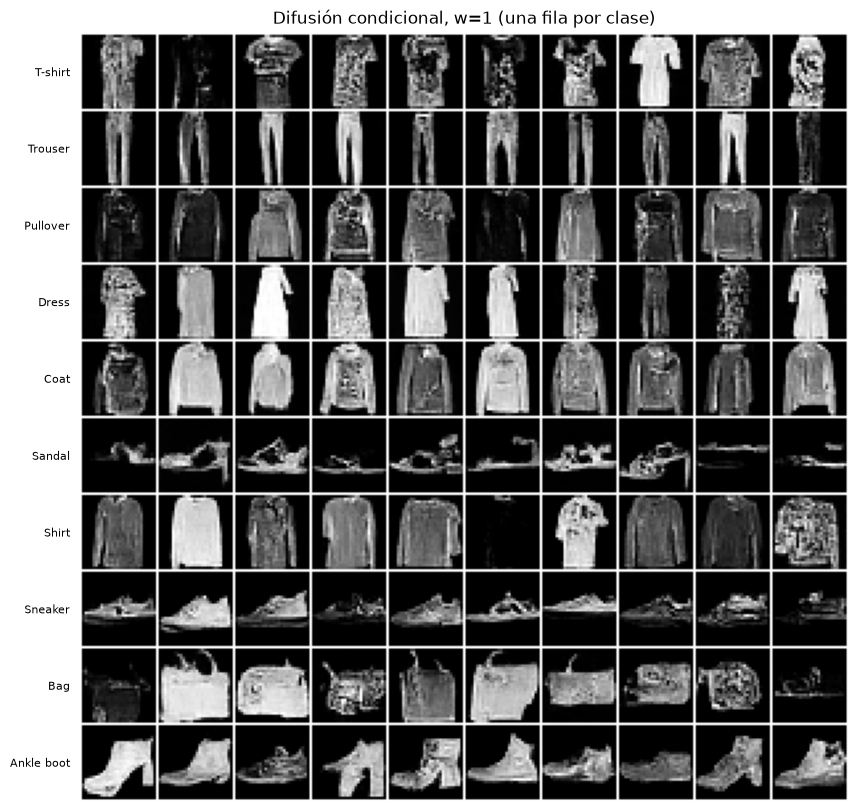

In [30]:
def generate(model, labels, w=1.0, sched=sched_lin, chunk=500, seed=None):
    """Muestreo por chunks; devuelve imágenes en [-1,1]."""
    model.eval()
    if seed is not None: torch.manual_seed(seed)
    return torch.cat([ancestral_sample(model, labels[i:i + chunk], sched, w) for i in range(0, len(labels), chunk)])

# Task 3.3: 10 imágenes por clase, w=1, una fila por clase
labels_33 = torch.arange(10, device=device).repeat_interleave(10)
samples_33 = generate(model_diff, labels_33, w=1.0, seed=SEED)
fig, ax = plt.subplots(figsize=(10, 10))
show(to01(samples_33), nrow=10, title="Difusión condicional, w=1 (una fila por clase)", ax=ax)
for i, n in enumerate(CLASS_NAMES): ax.text(-4, 1 + i * 29 + 14, n, ha="right", va="center", fontsize=8)
plt.show()

## Task 3.4(b–d) — Guía con $w\in\{1,3,7\}$, fidelidad, diversidad, tiempo
Clasificador sencillo entrenado sobre imágenes reales hasta ≥ 88 % de exactitud en validación. Diversidad = distancia euclidiana media entre pares de imágenes generadas de la misma clase (promediada sobre clases); referencia con 50 imágenes reales por clase.

In [31]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

@torch.no_grad()
def accuracy(clf, X, y):
    clf.eval(); return sum((clf(xb).argmax(1) == yb).sum().item() for xb, yb in batches(X, y, bs=1000, shuffle=False)) / len(X)

def train_classifier(target=0.88, max_epochs=15, path="ckpt/clf.pt"):
    torch.manual_seed(SEED)
    clf = SmallCNN().to(device)
    if os.path.exists(path) and not FORCE_RETRAIN:
        clf.load_state_dict(torch.load(path, map_location=device)); print("clasificador cargado, acc val =", accuracy(clf, X_val, y_val)); return clf
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    for ep in range(max_epochs):
        clf.train()
        for xb, yb in batches(X_train, y_train, bs=128):
            loss = F.cross_entropy(clf(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
        acc = accuracy(clf, X_val, y_val); print(f"clf ep {ep+1} | acc val {acc:.4f}")
        if acc >= target: break
    assert acc >= target, f"el clasificador no alcanzó {target:.0%}"
    torch.save(clf.state_dict(), path); return clf

clf = train_classifier()

@torch.no_grad()
def fidelity(clf, imgs01, labels):
    clf.eval(); return (clf(imgs01).argmax(1) == labels).float().mean().item()

@torch.no_grad()
def diversity_per_class(imgs01, labels):
    """Distancia euclidiana media entre pares (i<j) dentro de cada clase -> tensor (10,)."""
    out = []
    for c in range(10):
        f = imgs01[labels == c].flatten(1); n = len(f)
        d = torch.cdist(f, f)
        out.append(d.sum() / (n * (n - 1)))
    return torch.stack(out)

clasificador cargado, acc val = 0.8874


In [32]:
N_PER_CLASS, W_VALUES = 50, [1, 3, 7]
labels_gen = torch.arange(10, device=device).repeat_interleave(N_PER_CLASS)

gen = {}      # w -> dict(imgs [-1,1], fid, div_pc, sec_per_100)
for w in W_VALUES:
    torch.cuda.synchronize(); t0 = time.time()
    imgs = generate(model_diff, labels_gen, w=float(w), seed=SEED + w)
    torch.cuda.synchronize(); dt = time.time() - t0
    gen[w] = {"imgs": imgs, "fid": fidelity(clf, to01(imgs), labels_gen),
              "div_pc": diversity_per_class(to01(imgs), labels_gen), "sec_per_100": dt / len(imgs) * 100}
    print(f"w={w}: fidelidad {gen[w]['fid']:.3f} | diversidad {gen[w]['div_pc'].mean():.3f} | {gen[w]['sec_per_100']:.1f} s/100 imgs")

# referencia: 50 imágenes reales por clase (de validación)
real_idx = torch.cat([(y_val == c).nonzero()[:50, 0] for c in range(10)])
div_real_pc = diversity_per_class(X_val[real_idx], y_val[real_idx])

tab_guid = pd.DataFrame({
    "w": W_VALUES,
    "fidelidad": [gen[w]["fid"] for w in W_VALUES],
    "diversidad": [gen[w]["div_pc"].mean().item() for w in W_VALUES],
    "s / 100 imgs": [gen[w]["sec_per_100"] for w in W_VALUES]}).set_index("w")
print(f"diversidad de referencia (real, 50/clase): {div_real_pc.mean():.3f}")
tab_guid.round(3)

w=1: fidelidad 0.784 | diversidad 7.937 | 2.8 s/100 imgs
w=3: fidelidad 0.952 | diversidad 7.880 | 6.8 s/100 imgs
w=7: fidelidad 0.878 | diversidad 7.592 | 6.1 s/100 imgs
diversidad de referencia (real, 50/clase): 8.838


,fidelidad,diversidad,s / 100 imgs
w,,,
1,0.784,7.937,2.807
3,0.952,7.880,6.831
7,0.878,7.592,6.133


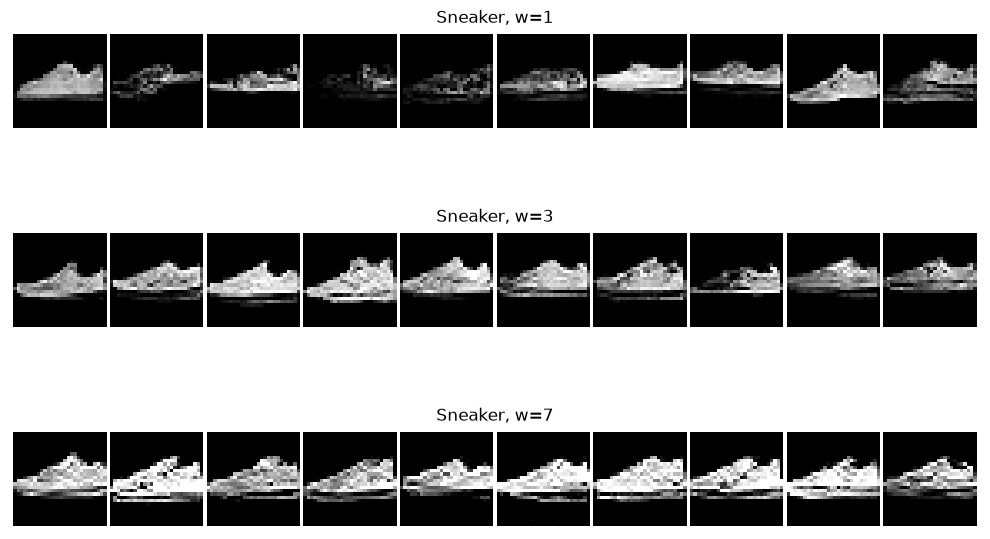

In [33]:
SHOW_CLASS = 7      # Sneaker (cambie a su gusto)
fig, axs = plt.subplots(len(W_VALUES), 1, figsize=(10, 2.2 * len(W_VALUES)))
for ax, w in zip(axs, W_VALUES):
    sel = (labels_gen == SHOW_CLASS).nonzero()[:10, 0]
    show(to01(gen[w]["imgs"][sel]), nrow=1, title=f"{CLASS_NAMES[SHOW_CLASS]}, w={w}", ax=ax)
plt.tight_layout(); plt.show()

## Task 3.5 — Análisis

### Pregunta 3.5(a)

**(a)** Cambio de fidelidad y diversidad con $w$; clase cuya diversidad más cae entre $w=1$ y $w=7$.

In [34]:
div_tab = pd.DataFrame({"real": div_real_pc.cpu().numpy(), **{f"w={w}": gen[w]["div_pc"].cpu().numpy() for w in W_VALUES}},
                       index=CLASS_NAMES)
div_tab["caída w1→w7 (%)"] = 100 * (div_tab["w=1"] - div_tab["w=7"]) / div_tab["w=1"]
print("clase más afectada:", div_tab["caída w1→w7 (%)"].idxmax())
div_tab.round(3)

clase más afectada: Bag


,real,w=1,w=3,w=7,caída w1→w7 (%)
T-shirt,9.371,7.623,9.735,11.727,-53.831001
Trouser,7.235,6.412,5.440,5.095,20.539000
Pullover,9.279,7.037,7.018,6.666,5.266000
Dress,8.056,8.591,7.805,8.806,-2.497000
Coat,8.448,8.771,6.548,5.175,40.997002
Sandal,9.458,6.909,8.641,12.377,-79.153999
Shirt,9.997,9.403,9.740,6.961,25.962000
Sneaker,6.372,6.066,6.021,6.707,-10.561000
Bag,11.320,10.575,10.599,5.208,50.750999
Ankle boot,8.839,7.988,7.251,7.197,9.895000


#### Respuesta 3.5(a)

| $w$ | fidelidad | diversidad | s / 100 imgs |
|---|---|---|---|
| 1 | 0.784 | 7.937 | 2.8 |
| 3 | 0.952 | 7.880 | 6.8 |
| 7 | 0.878 | 7.592 | 6.1 |

(Diversidad de referencia con 50 imágenes reales por clase: 8.838.)

**Tendencia.** La fidelidad sube de 0.784 a 0.952 al pasar de $w=1$ a $w=3$ (+17 puntos), pero baja a 0.878 con $w=7$: pasarse de guía deja de ayudar. La diversidad media cae de forma monótona (7.937 → 7.880 → 7.592, −4.3 % de $w=1$ a $w=7$) y ya con $w=1$ queda por debajo de la real (8.838). Además, $w\neq1$ duplica el batch de la red en cada paso, por eso el tiempo pasa de 2.8 a 6–7 s por 100 imágenes.

**Clase más afectada: Bag**, cuya diversidad cae de 10.575 ($w=1$) a 5.208 ($w=7$), −50.8 %. Le siguen Coat (8.771 → 5.175, −41.0 %), Shirt (−26.0 %) y Trouser (−20.5 %).

**Hipótesis (respaldada por los datos).** Bag es la clase con mayor diversidad real (11.320, la más alta de las 10): sus imágenes varían muchísimo (formas, asas, patrones), así que tiene más diversidad que perder. La guía empuja hacia lo que el modelo considera más típico de la clase; en una clase tan heterogénea eso colapsa a unos pocos prototipos, y por eso cae más: con $w=7$ su diversidad (5.208) queda en menos de la mitad de la real (11.320).

**Matiz sobre la métrica.** Algunas clases suben (T-shirt +54 %, Sandal +79 %, Sneaker +11 %). Con $w=7$ las imágenes salen saturadas y de mayor contraste, y la distancia euclidiana en píxeles crece con la intensidad, así que la métrica puede subir aunque la variedad de formas baje. Sneaker es el caso más claro: en la figura, con $w=7$ las 10 muestras son casi la misma zapatilla de alto contraste, pero su diversidad medida sube de 6.066 a 6.707. Es una limitación de usar distancia en píxeles como medida de diversidad.

### Pregunta 3.5(b)

**(b)** Matriz de confusión del clasificador sobre las imágenes generadas con $w=1$.

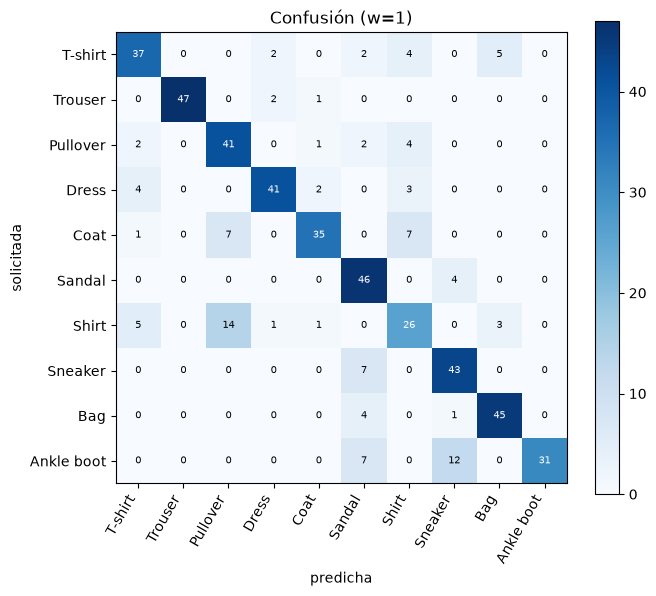

mayor confusión: solicitada Shirt -> predicha Pullover (14 imágenes)


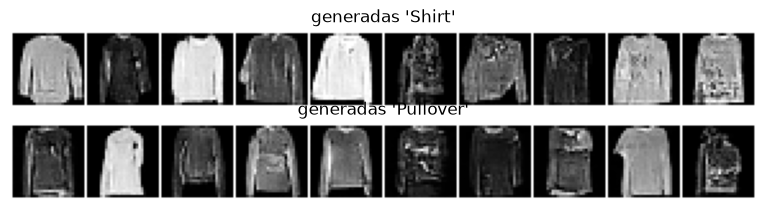

In [35]:
pred_w1 = clf(to01(gen[1]["imgs"])).argmax(1)
conf = torch.zeros(10, 10, dtype=torch.long)
for yt, yp in zip(labels_gen.cpu(), pred_w1.cpu()): conf[yt, yp] += 1
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(conf, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
ax.set(xlabel="predicha", ylabel="solicitada", title="Confusión (w=1)")
for i in range(10):
    for j in range(10): ax.text(j, i, int(conf[i, j]), ha="center", va="center", fontsize=7, color="w" if conf[i, j] > conf.max() / 2 else "k")
plt.colorbar(im); plt.tight_layout(); plt.show()

off = conf.clone(); off.fill_diagonal_(0)
a_, b_ = divmod(int(off.argmax()), 10)
print(f"mayor confusión: solicitada {CLASS_NAMES[a_]} -> predicha {CLASS_NAMES[b_]} ({off[a_, b_].item()} imágenes)")
sel_a = (labels_gen == a_).nonzero()[:10, 0]; sel_b = (labels_gen == b_).nonzero()[:10, 0]
fig, axs = plt.subplots(2, 1, figsize=(10, 2.2))
show(to01(gen[1]["imgs"][sel_a]), 1, f"generadas '{CLASS_NAMES[a_]}'", ax=axs[0]); show(to01(gen[1]["imgs"][sel_b]), 1, f"generadas '{CLASS_NAMES[b_]}'", ax=axs[1]); plt.show()

#### Respuesta 3.5(b)

La exactitud global con $w=1$ es $392/500=0.784$ (suma de la diagonal). El par más confundido es **Shirt → Pullover** (14 de 50 imágenes pedidas como Shirt). Shirt es además la clase peor lograda: solo 26/50 (52 %) se clasifican como Shirt. Le siguen Ankle boot → Sneaker (12), y con 7 cada una: Coat → Pullover, Coat → Shirt, Sneaker → Sandal y Ankle boot → Sandal.

**¿Defecto del generador, del clasificador o de las clases?** Principalmente de las propias clases, con una contribución del generador:
- **Clases:** Shirt, Pullover y Coat son prendas de torso con manga larga muy parecidas (y T-shirt comparte la misma silueta de torso). En las imágenes, las filas generadas de Shirt y Pullover son casi indistinguibles (mangas largas, cuerpo oscuro con textura), y lo mismo pasa con Ankle boot y Sneaker (calzado de perfil similar). Las confusiones ocurren justo entre grupos visualmente parecidos.
- **Generador:** con $w=1$ varias muestras salen ruidosas, de bajo contraste o con textura rara (se ve en la cuadrícula de la Task 3.3, p. ej. las filas de T-shirt y Dress), y esas muestras ambiguas son las que el clasificador confunde. La fidelidad sube a 0.952 con $w=3$, es decir, parte del error es del condicionamiento débil de $w=1$.
- **Clasificador:** su exactitud en validación es 0.8874, apenas sobre el 88 % pedido, así que también se equivoca. No calculé su matriz de confusión sobre datos reales; para confirmar que sus errores caen en los mismos pares habría que hacerlo.

### Pregunta 3.5(c)

**(c)** Demuestre que la guía corresponde a muestrear $\tilde p(x|c)\propto p(x)p(c|x)^w$ (en su informe: use $s\approx-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$ y Bayes sobre los gradientes de los logaritmos) y explique qué pasa con la diversidad cuando $w$ crece.

#### Respuesta 3.5(c)

*Demostración.* Con $s(x_t\mid c)\approx-\epsilon_\theta(x_t,t,c)/\sqrt{1-\bar\alpha_t}$ y $s(x_t)\approx-\epsilon_\theta(x_t,t,\varnothing)/\sqrt{1-\bar\alpha_t}$, la predicción guiada $\tilde\epsilon=\epsilon_\varnothing+w(\epsilon_c-\epsilon_\varnothing)$ corresponde al score
$$\tilde s=s_\varnothing+w\,(s_c-s_\varnothing)=\nabla\log p(x)+w\left[\nabla\log p(x\mid c)-\nabla\log p(x)\right].$$
Por la regla de Bayes, $p(x\mid c)=p(c\mid x)p(x)/p(c)$, y como $p(c)$ no depende de $x$, al tomar el gradiente del logaritmo:
$$\nabla\log p(x\mid c)-\nabla\log p(x)=\nabla\log p(c\mid x).$$
Entonces
$$\tilde s=\nabla\log p(x)+w\,\nabla\log p(c\mid x)=\nabla\log\!\left[p(x)\,p(c\mid x)^w\right],$$
es decir, se muestrea de $\tilde p(x\mid c)\propto p(x)\,p(c\mid x)^w$. Para $w=1$ es $p(x)p(c|x)\propto p(x|c)$ (el modelo condicional puro), y para $w=0$ es $p(x)$ (incondicional).

*Efecto sobre la diversidad.* Elevar $p(c\mid x)$ a $w>1$ amplifica las diferencias: las imágenes donde la clase es muy clara pesan mucho más y las ambiguas casi desaparecen (algo parecido a bajar la temperatura). La masa se concentra en pocos modos típicos de la clase y la diversidad baja. Es lo que se ve en los datos: diversidad 7.937 → 7.880 → 7.592 para $w=1,3,7$, con la caída más fuerte en Bag (−50.8 %). La fidelidad sube primero (0.784 → 0.952), pero con $w=7$ baja a 0.878: un factor tan grande lleva a pasos fuera de la distribución de datos y a imágenes saturadas.

### Pregunta 3.5(d)

**(d)** Intervalo de $t$ con mayor y menor pérdida (Task 3.2) y relación con el SNR y la Task 2.5(b).

#### Respuesta 3.5(d)

MSE de validación por intervalo de $t$:

| intervalo | 1–100 | 101–200 | 201–300 | 301–400 | 401–500 | 501–600 | 601–700 | 701–800 | 801–900 | 901–1000 |
|---|---|---|---|---|---|---|---|---|---|---|
| MSE | 0.2145 | 0.0826 | 0.0478 | 0.0287 | 0.0162 | 0.0080 | 0.0036 | 0.0017 | 0.0011 | 0.0010 |

La pérdida es **mayor en el intervalo 1–100 (0.2145)** y **menor en el 901–1000 (0.0010)**, unas 215 veces menor, y decrece de forma monótona. Los dos primeros intervalos concentran el 73 % de la suma de las pérdidas.

**Relación con el SNR (Task 2.5b).** Con SNR alto ($t$ pequeño) $x_t\approx x_0$ y el ruido es una perturbación mínima que la red solo puede separar si reconoce el detalle fino de la imagen: la tarea es la más difícil. En el calendario lineal, los primeros ~27 pasos tienen SNR $>100$ y el SNR cruza 1 en $t=260$. Con SNR bajo, $x_t\approx\epsilon$ y predecir $\epsilon$ se reduce a copiar $x_t$ (reescalado): en el calendario lineal los 326 pasos con SNR $<0.01$ ($t\ge675$) cubren los intervalos 701–1000 y el final del 601–700, donde la pérdida es $\le0.0036$.

**¿Coincide con lo que predije?** Sí. En 2.5(b) anticipé que los pasos de SNR muy alto serían los más difíciles y los de SNR muy bajo casi triviales, y la gráfica lo confirma. Además, estos últimos aportan muy poco gradiente cuando $t$ se sortea uniformemente, lo que explica por qué el calendario propio (coseno), con 880 pasos en el rango informativo contra 647, es más eficiente.

# Task 4 — Comparación de familias y pass@k (Entrega final)

## Task 4.1 — VAE vs. difusión

### Pregunta 4.1(a)

**(a)** Nitidez (Task 1.4d) sobre 500 imágenes de difusión con $w=1$, 500 del VAE con $\beta=1$ y 500 reales. (Todo se lleva a $[0,1]$ antes de medir.)

In [36]:
sharp_cmp = pd.DataFrame({"nitidez": {
    "difusión (w=1)": sharpness(to01(gen[1]["imgs"][:500])),
    "VAE (β=1)": sharpness(vae_sample(vaes[1.0], 500, seed=SEED)),
    "real": sharpness(X_val[:500])}})
sharp_cmp.round(4)

,nitidez
difusión (w=1),0.0739
VAE (β=1),0.0508
real,0.0886


#### Respuesta 4.1(a)

| | nitidez | % de la real |
|---|---|---|
| Real | 0.0886 | 100 % |
| Difusión ($w=1$) | 0.0739 | 83 % |
| VAE ($\beta=1$) | 0.0508 | 57 % |

### Pregunta 4.1(b)

**(b)** Tiempo de generación de 100 imágenes y número de evaluaciones de red (VAE vs. difusión sin guía).

In [37]:
@contextmanager
def count_forward_calls(module):
    """Cuenta cuántas veces se llama `module.forward` (una llamada = una evaluación de red sobre el batch)."""
    n = {"calls": 0}
    h = module.register_forward_hook(lambda *_: n.__setitem__("calls", n["calls"] + 1))
    try: yield n
    finally: h.remove()

def timed(fn):
    torch.cuda.synchronize(); t0 = time.time(); out = fn(); torch.cuda.synchronize(); return out, time.time() - t0

lab100 = torch.arange(10, device=device).repeat_interleave(10)
_, t_vae = timed(lambda: vae_sample(vaes[1.0], 100, seed=SEED))
with count_forward_calls(model_diff) as n_diff:
    _, t_diff = timed(lambda: generate(model_diff, lab100, w=1.0, seed=SEED))
n_vae_evals = 1     # una sola pasada por el decoder para las 100 imágenes
print(f"VAE     : {t_vae*1000:8.1f} ms | evaluaciones de red: {n_vae_evals}")
print(f"Difusión: {t_diff*1000:8.1f} ms | evaluaciones de red: {n_diff['calls']}  (T={T}, w=1)")
print(f"razón de tiempos difusión / VAE = {t_diff / t_vae:.0f}×")

VAE     :      0.3 ms | evaluaciones de red: 1
Difusión:   1785.6 ms | evaluaciones de red: 1000  (T=1000, w=1)
razón de tiempos difusión / VAE = 6341×


#### Respuesta 4.1(b)

| | tiempo (100 imgs) | evaluaciones de red |
|---|---|---|
| VAE ($\beta=1$) | 0.3 ms | 1 |
| Difusión ($w=1$) | 1785.6 ms | 1000 |

Razón de tiempos difusión / VAE $\approx$ **6341×**.

### Pregunta 4.1(c)

**(c)** Posición de cada implementación en el mapa de compensaciones (nitidez, velocidad, estabilidad de entrenamiento) y qué cambiaría para acortar la difusión.

#### Respuesta 4.1(c)

- **VAE:** rápido (una pasada del decoder) y estable (pérdida determinista, sin adversario), pero borroso: con MSE el decoder predice $\mathbb E[x\mid z]$ y promedia los bordes (Task 1.4d).
- **Difusión:** más nítida (83 % vs. 57 % de la nitidez real) y también estable (un MSE sencillo), pero ~6300× más lenta por sus $T=1000$ evaluaciones secuenciales.

Ambas ganan en estabilidad; la compensación real es **nitidez vs. velocidad**.

**Para acortar la difusión:** muestrear con menos pasos (p. ej. DDIM con ~50 pasos, ~20× menos evaluaciones), destilar el modelo a pocos pasos (destilación progresiva o modelos de consistencia) o usar una U-Net más pequeña. Además, evitar $w\neq1$, que duplica el batch y multiplica el costo por ~2.4 (6.8 vs. 2.8 s / 100 imgs).

## Task 4.2 — pass@k

Escriba el estimador insesgado $1-\binom{n-c}{k}/\binom nk$ (con valor 1 si $n-c<k$) y la versión ingenua $1-(1-c/n)^k$.

In [ ]:
def pass_at_k(n, c, k):
    if n - c < k: return 1.0
    return 1.0 - math.comb(n - c, k) / math.comb(n, k)


def pass_at_k_naive(n, c, k):
    return 1.0 - (1.0 - c / n) ** k

In [39]:
n = 20
problems = {"P1": 0, "P2": 2, "P3": 5, "P4": 9, "P5": 14, "P6": 20}     # c = soluciones correctas

tab_pass = pd.DataFrame({f"pass@{k}": {p: pass_at_k(n, c, k) for p, c in problems.items()} for k in (1, 5, 10)})
tab_pass.loc["promedio"] = tab_pass.mean()
tab_pass.round(4)

,pass@1,pass@5,pass@10
P1,0.0000,0.0000,0.0000
P2,0.1000,0.4474,0.7632
P3,0.2500,0.8063,0.9837
P4,0.4500,0.9702,0.9999
P5,0.7000,0.9996,1.0000
P6,1.0000,1.0000,1.0000
promedio,0.4167,0.7039,0.7911


### Pregunta 4.2(a)

**(a)** Pasos de P2 con $k=5$ (en su informe).

#### Respuesta 4.2(a)

| | pass@1 | pass@5 | pass@10 |
|---|---|---|---|
| P1 | 0.0000 | 0.0000 | 0.0000 |
| P2 | 0.1000 | 0.4474 | 0.7632 |
| P3 | 0.2500 | 0.8063 | 0.9837 |
| P4 | 0.4500 | 0.9702 | 0.9999 |
| P5 | 0.7000 | 0.9996 | 1.0000 |
| P6 | 1.0000 | 1.0000 | 1.0000 |
| **promedio** | **0.4167** | **0.7039** | **0.7911** |

**P2, $k=5$** ($n=20$, $c=2$, $n-c=18\ge5$):
$$\text{pass@5}=1-\frac{\binom{18}{5}}{\binom{20}{5}}=1-\frac{8568}{15504}=1-0.5526=\mathbf{0.4474}.$$

### Pregunta 4.2(b)

**(b)** P2: $\text{pass@}k=1-\frac{(20-k)(19-k)}{380}$ y menor $k$ con pass@$k>0.9$.

In [40]:
ks = np.arange(1, 21)
closed = 1 - (20 - ks) * (19 - ks) / 380
assert np.allclose(closed, [pass_at_k(20, 2, int(k)) for k in ks]), "la fórmula cerrada no coincide con su estimador"
print("menor k con pass@k > 0.9 en P2:", int(ks[closed > 0.9][0]))

menor k con pass@k > 0.9 en P2: 14


#### Respuesta 4.2(b)

*Demostración.* Para $n=20$, $c=2$:
$$\frac{\binom{18}{k}}{\binom{20}{k}}=\frac{18!}{k!\,(18-k)!}\cdot\frac{k!\,(20-k)!}{20!}=\frac{(20-k)(19-k)}{20\cdot19}=\frac{(20-k)(19-k)}{380}\ \Rightarrow\ \text{pass@}k=1-\frac{(20-k)(19-k)}{380}.$$
La celda verifica que coincide con el estimador para $k=1,\dots,20$.

*Menor $k$:* $k=13$ da $1-\frac{42}{380}=0.8895$ y $k=14$ da $1-\frac{30}{380}=0.9211$, así que **$k=14$**.

### Pregunta 4.2(c)

**(c)** Estimador insesgado vs. ingenuo, $k=5$ (la demostración de $\text{naive}\le\text{unbiased}$ va en su informe).

In [41]:
tab_cmp = pd.DataFrame({"insesgado": {p: pass_at_k(n, c, 5) for p, c in problems.items()},
                        "ingenuo":   {p: pass_at_k_naive(n, c, 5) for p, c in problems.items()}})
tab_cmp["diferencia"] = tab_cmp["insesgado"] - tab_cmp["ingenuo"]
assert (tab_cmp["diferencia"] >= -1e-12).all(), "el ingenuo no debería exceder al insesgado"
tab_cmp.round(4)

,insesgado,ingenuo,diferencia
P1,0.0000,0.0000,0.0000
P2,0.4474,0.4095,0.0379
P3,0.8063,0.7627,0.0436
P4,0.9702,0.9497,0.0205
P5,0.9996,0.9976,0.0020
P6,1.0000,1.0000,0.0000


#### Respuesta 4.2(c)

| | insesgado | ingenuo | diferencia |
|---|---|---|---|
| P1 | 0.0000 | 0.0000 | 0.0000 |
| P2 | 0.4474 | 0.4095 | 0.0379 |
| P3 | 0.8063 | 0.7627 | 0.0436 |
| P4 | 0.9702 | 0.9497 | 0.0205 |
| P5 | 0.9996 | 0.9976 | 0.0020 |
| P6 | 1.0000 | 1.0000 | 0.0000 |

El ingenuo nunca supera al insesgado; la brecha es mayor en los problemas intermedios (P2, P3) y nula en los extremos (P1, P6).

*Demostración.* Si $n-c<k$, el insesgado vale 1 $\ge$ ingenuo. Si $n-c\ge k$:
$$\frac{\binom{n-c}{k}}{\binom nk}=\prod_{i=0}^{k-1}\frac{n-c-i}{n-i}\le\left(\frac{n-c}{n}\right)^k=\left(1-\frac cn\right)^k,$$
y restando de 1 se invierte la desigualdad: ingenuo $\le$ insesgado.

El ingenuo muestrea con reemplazo; el insesgado, sin reemplazo, no repite soluciones fallidas y por eso es más probable que encuentre una correcta.

### Pregunta 4.2(d)

**(d)** Agente que reintenta hasta 10 veces con verificador perfecto: ¿qué problemas resuelve? ¿Qué dice la diferencia entre el promedio de pass@1 y el de pass@10?

#### Respuesta 4.2(d)

Con hasta 10 intentos y un verificador perfecto, el agente resuelve **P2–P6** (todos con $c>0$), con probabilidad pass@10: 0.76 en P2, 0.98 en P3 y $\ge0.9999$ en P4–P6. **P1** ($c=0$) no se resuelve nunca.

El promedio sube de **0.417** (pass@1) a **0.791** (pass@10), casi el doble. El modelo sabe resolver la mayoría de los problemas, pero no de forma consistente y reintentar con verificación compensa esa inconsistencia. El techo es $5/6\approx0.833$ (fracción con $c>0$); lo que falta (P1) requiere un mejor modelo, no más intentos